# When Docstrings Decide — analisis lengkap

Satu notebook ini menghasilkan **semua angka, tabel, dan figure** di `paper/main.tex`.

**Cara pakai:** `Run All`. Butuh Python 3.10+ dan paket di sel pertama.
Data (HumanEval, MBPP) diunduh otomatis ke `data/` kalau belum ada.
Kode benchmark hanya di-*parse* (ast/radon), tidak pernah dieksekusi.

Output:
- `results/metrics_all.csv` — metrik per program (1.138 baris)
- `results/humaneval_docstring_ablation.csv` — data ablasi
- `results/stats.json` — semua angka yang dikutip di paper
- `paper/figures/fig_comment_term.pdf`, `paper/figures/fig_ablation.pdf`

In [28]:
%pip install -q radon==6.0.1 scipy numpy pandas matplotlib pyarrow
import ast, gzip, json, math, shutil, urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import radon
from radon.complexity import cc_visit
from radon.metrics import h_visit_ast, mi_parameters, mi_visit
from radon.raw import analyze
from radon.visitors import ComplexityVisitor
from scipy.stats import spearmanr

DATA, RES, FIG = Path("data"), Path("results"), Path("paper/figures")
for p in (DATA, RES, FIG):
    p.mkdir(parents=True, exist_ok=True)
print("radon", radon.__version__)   # paper melaporkan 6.0.1

radon 6.0.1


## 1. Data

In [29]:
SOURCES = {
    "HumanEval.jsonl": "https://github.com/openai/human-eval/raw/master/data/HumanEval.jsonl.gz",
    "mbpp.jsonl": "https://raw.githubusercontent.com/google-research/google-research/master/mbpp/mbpp.jsonl",
}
for name, url in SOURCES.items():
    target = DATA / name
    if target.exists():
        continue
    raw = urllib.request.urlopen(url).read()
    target.write_bytes(gzip.decompress(raw) if url.endswith(".gz") else raw)

humaneval = [json.loads(l) for l in open(DATA / "HumanEval.jsonl", encoding="utf-8")]
mbpp = [json.loads(l) for l in open(DATA / "mbpp.jsonl", encoding="utf-8")]
len(humaneval), len(mbpp)   # (164, 974)

(164, 974)

## 2. Varian Maintainability Index

Semua varian memakai **input yang sama** dari radon (Halstead V, total CC, LLOC, persentase komentar),
jadi yang berbeda hanya rumusnya.

| Varian | Rumus |
|---|---|
| original (Oman & Hagemeister) | 171 − 5.2 ln V − 0.23 G − 16.2 ln L |
| SEI | original + 50 sin(√(2.4 · perCM)), perCM sebagai pecahan |
| Visual Studio | max(0, original · 100/171) |
| radon | `mi_visit` (koefisien 2.46, persen komentar dikonversi ke radian, clamp 0–100, V=0 → 100) |

In [30]:
def mi_original(v, g, loc):
    if v <= 0 or loc <= 0:
        return float("nan")
    return 171 - 5.2 * math.log(v) - 0.23 * g - 16.2 * math.log(loc)

def mi_sei(v, g, loc, cm_pct):
    if v <= 0 or loc <= 0:
        return float("nan")
    return mi_original(v, g, loc) + 50 * math.sin(math.sqrt(2.4 * cm_pct / 100.0))

def mi_vs(v, g, loc):
    if v <= 0 or loc <= 0:
        return float("nan")
    return max(0.0, mi_original(v, g, loc) * 100 / 171)

RADON_PEAK = math.degrees((math.pi / 2) ** 2 / 2.46)   # % komentar di puncak suku sinus radon
SEI_PEAK = 100 * (math.pi / 2) ** 2 / 2.4              # % komentar di puncak suku SEI
round(RADON_PEAK, 1), round(SEI_PEAK, 1)               # (57.5, 102.8)

(57.5, 102.8)

## 3. Pengukuran per program

In [31]:
import pandas as pd
# Fix for python 3.13 pandas KeyError: 'mode' and 'future' configuration issues
if "mode" not in pd._config.config._global_config:
    pd._config.config._global_config["mode"] = {
        "copy_on_write": False,
        "data_manager": "array",
        "chained_assignment": "warn",
    }
if "future" not in pd._config.config._global_config:
    pd._config.config._global_config["future"] = {
        "infer_string": False,
    }

def strip_docstrings(tree):
    for node in ast.walk(tree):
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            b = node.body
            if b and isinstance(b[0], ast.Expr) and isinstance(getattr(b[0], "value", None), ast.Constant) \
                    and isinstance(b[0].value.value, str):
                node.body = b[1:] or [ast.Pass()]
    return tree

def measure(code):
    tree = ast.parse(code)
    raw = analyze(code)
    v, g, lloc, cm = mi_parameters(code, count_multi=True)
    h = h_visit_ast(tree).total
    return {
        "loc": raw.loc, "sloc": raw.sloc, "lloc": raw.lloc,
        "comment_lines": raw.comments, "multi_lines": raw.multi, "comment_pct": cm,
        "cc_total": ComplexityVisitor.from_ast(tree).total_complexity,
        "h_volume": h.volume, "h_difficulty": h.difficulty,
        "mi_radon": mi_visit(code, multi=True),
        "mi_original": mi_original(v, g, lloc), "mi_sei": mi_sei(v, g, lloc, cm), "mi_vs": mi_vs(v, g, lloc),
        "zero_volume": v <= 0,
    }

nonblank = lambda s: len([l for l in s.splitlines() if l.strip()])
rows, abl = [], []

for p in humaneval:
    full = p["prompt"] + p["canonical_solution"]          # protokol standar HumanEval
    pl, bl = nonblank(p["prompt"]), nonblank(p["canonical_solution"])
    rows.append({"benchmark": "HumanEval", "task_id": p["task_id"], "prompt_nonblank": pl,
                 "body_nonblank": bl, "prompt_share": pl / (pl + bl), **measure(full)})
    # Ablasi: kode identik (dinormalisasi ast.unparse), docstring dipertahankan vs dibuang
    a = {"task_id": p["task_id"]}
    for tag, src in (("with", ast.unparse(ast.parse(full))),
                     ("without", ast.unparse(strip_docstrings(ast.parse(full))))):
        m = measure(src)
        for k in ("lloc", "comment_pct", "cc_total", "h_volume", "mi_radon", "mi_sei", "mi_vs", "zero_volume"):
            a[f"{k}_{tag}"] = m[k]
    abl.append(a)

for p in mbpp:
    code_ = p["code"].replace("\r\n", "\n").replace("\t", "    ")
    rows.append({"benchmark": "MBPP", "task_id": f"MBPP/{p['task_id']}", "prompt_nonblank": 0,
                 "body_nonblank": nonblank(code_), "prompt_share": 0.0, **measure(code_)})

d, ab = pd.DataFrame(rows), pd.DataFrame(abl)
d.to_csv(RES / "metrics_all.csv", index=False)
ab.to_csv(RES / "humaneval_docstring_ablation.csv", index=False)
d.groupby("benchmark").size()

<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\*'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\W'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:4: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: invalid escape sequence '\w'
<unknown>:3: SyntaxWarning: inv

,0
benchmark,
HumanEval,164
MBPP,974


## 4. RQ1 — Distribusi (Tabel I)

In [32]:
def med_iqr(s):
    s = s.dropna()
    return f"{s.median():.2f} [{s.quantile(.25):.2f}, {s.quantile(.75):.2f}]"

cols = ["loc", "lloc", "comment_pct", "cc_total", "h_volume", "prompt_share", "mi_radon", "mi_vs"]
table1 = pd.DataFrame({b: {c: med_iqr(g[c]) for c in cols} for b, g in d.groupby("benchmark")})
counts = d.groupby("benchmark").agg(
    n=("task_id", "size"),
    beyond_radon_peak=("comment_pct", lambda s: int((s > RADON_PEAK).sum())),
    zero_comment=("comment_pct", lambda s: int((s == 0).sum())),
    zero_volume=("zero_volume", "sum"),
    mi_radon_100=("mi_radon", lambda s: int((s >= 100).sum())),
).T
display(table1, counts)

,HumanEval,MBPP
loc,"19.00 [15.00, 25.00]","5.00 [3.00, 9.00]"
lloc,"8.00 [5.00, 11.00]","5.00 [4.00, 9.00]"
comment_pct,"142.86 [100.00, 250.00]","0.00 [0.00, 0.00]"
cc_total,"3.00 [2.00, 4.25]","2.00 [1.00, 4.00]"
h_volume,"29.77 [4.75, 67.09]","15.51 [2.00, 60.77]"
prompt_share,"0.66 [0.55, 0.84]","0.00 [0.00, 0.00]"
mi_radon,"86.53 [75.08, 93.01]","76.77 [67.48, 87.22]"
mi_vs,"68.52 [63.98, 74.89]","72.82 [65.47, 79.74]"


benchmark,HumanEval,MBPP
n,164,974
beyond_radon_peak,154,0
zero_comment,0,971
zero_volume,15,233
mi_radon_100,23,233


In [33]:
# Berapa variasi MI radon yang berasal dari suku komentar vs suku struktural (HumanEval, V>0)
he = d[(d.benchmark == "HumanEval") & ~d.zero_volume]
comment_term = 50 * np.sin(np.sqrt(2.46 * np.radians(he.comment_pct))) * 100 / 171
struct_term = he.mi_original * 100 / 171
round(comment_term.std(), 2), round(struct_term.std(), 2)   # paper: 19.2 vs 8.1

(19.24, 8.08)

## 5. RQ2 — Apa yang diikuti tiap varian (Tabel II)

In [34]:
def rho(a, b):
    r, p = spearmanr(a, b)
    return round(float(r), 3), float(f"{p:.2g}")

def boot_ci(a, b, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    vals = [spearmanr(a[i], b[i])[0] for i in (rng.integers(0, len(a), len(a)) for _ in range(n))]
    return [round(float(x), 3) for x in np.nanpercentile(vals, [2.5, 97.5])]

table2, agree = [], {}
for b, g in d[~d.zero_volume].groupby("benchmark"):
    for mi in ("mi_radon", "mi_sei", "mi_vs"):
        table2.append({"benchmark": b, "n": len(g), "variant": mi,
                       **{x: rho(g[mi], g[x])[0] for x in ("cc_total", "h_volume", "lloc", "comment_pct")}})
    agree[b] = {"radon~vs": rho(g.mi_radon, g.mi_vs), "radon~vs CI": boot_ci(g.mi_radon, g.mi_vs),
                "radon~sei": rho(g.mi_radon, g.mi_sei), "sei~vs": rho(g.mi_sei, g.mi_vs)}
display(pd.DataFrame(table2), pd.DataFrame(agree))

,benchmark,n,variant,cc_total,h_volume,lloc,comment_pct
0,HumanEval,149,mi_radon,0.175,0.003,0.442,-0.815
1,HumanEval,149,mi_sei,-0.195,-0.320,-0.131,-0.249
2,HumanEval,149,mi_vs,-0.730,-0.838,-0.923,0.690
3,MBPP,741,mi_radon,-0.748,-0.858,-0.928,0.051
4,MBPP,741,mi_sei,-0.749,-0.859,-0.930,0.030
5,MBPP,741,mi_vs,-0.749,-0.861,-0.931,-0.034


,HumanEval,MBPP
radon~vs,"(-0.29, 0.00033)","(0.996, 0.0)"
radon~vs CI,"[-0.431, -0.123]","[0.989, 1.0]"
radon~sei,"(0.641, 1.2e-18)","(1.0, 0.0)"
sei~vs,"(0.227, 0.0055)","(0.998, 0.0)"


In [35]:
# Dua contoh di §IV-B
d.set_index("task_id").loc[["HumanEval/157", "HumanEval/9"],
    ["lloc", "comment_pct", "cc_total", "h_volume", "mi_radon", "mi_vs"]].round(2)

,lloc,comment_pct,cc_total,h_volume,mi_radon,mi_vs
task_id,,,,,,
HumanEval/157,3,450.00,3,218.51,45.02,72.81
HumanEval/9,12,45.45,3,4.75,100.00,71.31


## 6. RQ3 — Ablasi docstring (Tabel III)

In [36]:
ok = ab[~ab.zero_volume_with & ~ab.zero_volume_without]
assert (ok.cc_total_with == ok.cc_total_without).all()          # CC identik
assert np.allclose(ok.h_volume_with, ok.h_volume_without)        # Halstead V identik

table3 = {}
for tag in ("with", "without"):
    table3[tag] = {
        "median comment %": round(ok[f"comment_pct_{tag}"].median(), 1),
        "median radon MI": round(ok[f"mi_radon_{tag}"].median(), 1),
        **{f"radon vs {x}": rho(ok[f"mi_radon_{tag}"], ok[f"{x}_{tag}"])[0] for x in ("cc_total", "h_volume", "lloc")},
        "radon vs VS": rho(ok[f"mi_radon_{tag}"], ok[f"mi_vs_{tag}"])[0],
    }
same_code = {
    "n": len(ok),
    "LLOC diff (median)": float((ok.lloc_with - ok.lloc_without).median()),
    "radon kept~removed": rho(ok.mi_radon_with, ok.mi_radon_without),
    "radon kept~removed CI": boot_ci(ok.mi_radon_with, ok.mi_radon_without),
    "SEI kept~removed": rho(ok.mi_sei_with, ok.mi_sei_without),
    "VS kept~removed": rho(ok.mi_vs_with, ok.mi_vs_without),
    "median |rank shift|": float((ok.mi_radon_with.rank() - ok.mi_radon_without.rank()).abs().median()),
}
display(pd.DataFrame(table3), same_code)

,with,without
median comment %,133.300,0.000
median radon MI,85.100,69.800
radon vs cc_total,0.182,-0.729
radon vs h_volume,-0.001,-0.810
radon vs lloc,0.445,-0.937
radon vs VS,-0.290,1.000


{'n': 149,
 'LLOC diff (median)': 1.0,
 'radon kept~removed': (-0.313, 0.0001),
 'radon kept~removed CI': [-0.452, -0.145],
 'SEI kept~removed': (0.238, 0.0035),
 'VS kept~removed': (0.998, 3.9e-174),
 'median |rank shift|': 58.5}

## 7. Simpan semua angka

In [37]:
stats = {
    "radon_version": radon.__version__,
    "radon_peak_pct": round(RADON_PEAK, 1), "sei_peak_pct": round(SEI_PEAK, 1),
    "table1": table1.to_dict(), "counts": counts.astype(int).to_dict(),
    "term_sd": {"comment": round(float(comment_term.std()), 2), "structural": round(float(struct_term.std()), 2)},
    "table2": table2, "variant_agreement": agree,
    "table3": table3, "ablation_same_code": same_code,
}
(RES / "stats.json").write_text(json.dumps(stats, indent=2, default=str))
print("saved", RES / "stats.json")

saved results/stats.json


## 8. Figure

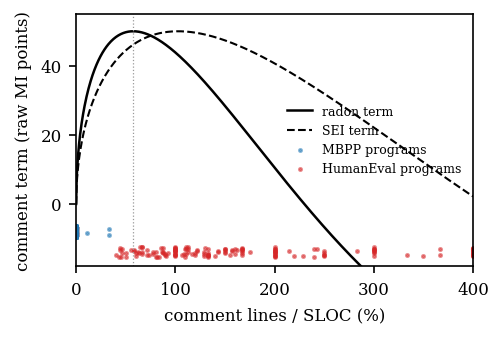

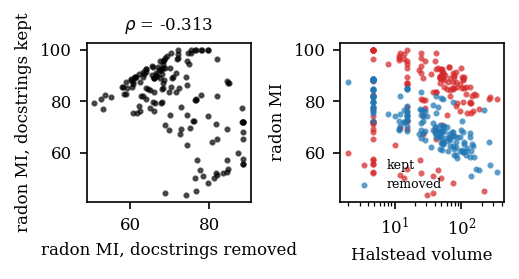

In [38]:
plt.rcParams.update({"font.size": 8, "font.family": "serif", "figure.dpi": 150})

# Fig. 1 — suku komentar dan posisi tiap benchmark
fig, ax = plt.subplots(figsize=(3.4, 2.3))
x = np.linspace(0, 400, 800)
ax.plot(x, 50 * np.sin(np.sqrt(2.46 * np.radians(x))), "k-", lw=1.2, label="radon term")
ax.plot(x, 50 * np.sin(np.sqrt(2.4 * x / 100)), "k--", lw=1.0, label="SEI term")
ax.axvline(RADON_PEAK, color="0.6", lw=0.6, ls=":")
for b, c, yoff in (("MBPP", "#1f77b4", -8), ("HumanEval", "#d62728", -14)):
    s = d[d.benchmark == b].comment_pct.clip(upper=400)
    ax.scatter(s, yoff + np.random.default_rng(1).uniform(-1.5, 1.5, len(s)), s=2, color=c, alpha=.5,
               label=f"{b} programs")
ax.set(xlabel="comment lines / SLOC (%)", ylabel="comment term (raw MI points)", xlim=(0, 400), ylim=(-18, 55))
ax.legend(loc="center right", fontsize=6, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig_comment_term.pdf"); plt.show()

# Fig. 2 — ablasi
fig, axs = plt.subplots(1, 2, figsize=(3.5, 1.9))
axs[0].scatter(ok.mi_radon_without, ok.mi_radon_with, s=4, color="k", alpha=.6)
axs[0].set(xlabel="radon MI, docstrings removed", ylabel="radon MI, docstrings kept")
axs[0].set_title(f"$\\rho$ = {same_code['radon kept~removed'][0]:+.3f}", fontsize=8)
axs[1].scatter(ok.h_volume_with, ok.mi_radon_with, s=4, color="#d62728", alpha=.6, label="kept")
axs[1].scatter(ok.h_volume_without, ok.mi_radon_without, s=4, color="#1f77b4", alpha=.6, label="removed")
axs[1].set(xscale="log", xlabel="Halstead volume", ylabel="radon MI")
axs[1].legend(fontsize=6, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig_ablation.pdf"); plt.show()

## 9. Replikasi di BigCodeBench (Complete)

BigCodeBench-Complete juga memakai prompt berisi docstring terstruktur; analisisnya sama dengan HumanEval
(`complete_prompt + canonical_solution`), versi data v0.1.4 (1.140 soal).

In [39]:
BCB = DATA / "bigcodebench_v0.1.4.parquet"
if not BCB.exists():
    BCB.write_bytes(urllib.request.urlopen(
        "https://huggingface.co/datasets/bigcode/bigcodebench/resolve/refs%2Fconvert%2Fparquet/default/v0.1.4/0000.parquet").read())
bcb = pd.read_parquet(BCB)

brow, babl = [], []
for _, p in bcb.iterrows():
    full = p.complete_prompt + p.canonical_solution
    pl, bl = nonblank(p.complete_prompt), nonblank(p.canonical_solution)
    brow.append({"task_id": p.task_id, "prompt_share": pl / (pl + bl), **measure(full)})
    a = {"task_id": p.task_id}
    for tag, src in (("with", ast.unparse(ast.parse(full))),
                     ("without", ast.unparse(strip_docstrings(ast.parse(full))))):
        m = measure(src)
        for k in ("lloc", "comment_pct", "cc_total", "h_volume", "mi_radon", "mi_sei", "mi_vs", "zero_volume"):
            a[f"{k}_{tag}"] = m[k]
    babl.append(a)
bd, bab = pd.DataFrame(brow), pd.DataFrame(babl)
bd.to_csv(RES / "bigcodebench_metrics.csv", index=False)
bab.to_csv(RES / "bigcodebench_docstring_ablation.csv", index=False)

bnz = bd[~bd.zero_volume]
bok = bab[~bab.zero_volume_with & ~bab.zero_volume_without]
assert (bok.cc_total_with == bok.cc_total_without).all() and np.allclose(bok.h_volume_with, bok.h_volume_without)
stats_bcb = {
    "n": len(bd), "zero_volume": int(bd.zero_volume.sum()),
    "beyond_radon_peak": int((bd.comment_pct > RADON_PEAK).sum()),
    "comment_pct": med_iqr(bd.comment_pct), "prompt_share": med_iqr(bd.prompt_share),
    "lloc": med_iqr(bd.lloc), "cc_total": med_iqr(bd.cc_total), "h_volume": med_iqr(bd.h_volume),
    "mi_radon": med_iqr(bd.mi_radon), "mi_vs": med_iqr(bnz.mi_vs),
    "n_nonzero_volume": len(bnz),
    **{f"{mi} vs {x}": rho(bnz[mi], bnz[x])[0] for mi in ("mi_radon", "mi_sei", "mi_vs")
       for x in ("cc_total", "h_volume", "lloc", "comment_pct")},
    "radon~vs": rho(bnz.mi_radon, bnz.mi_vs), "radon~vs CI": boot_ci(bnz.mi_radon, bnz.mi_vs),
    "ablation n": len(bok),
    "radon kept~removed": rho(bok.mi_radon_with, bok.mi_radon_without),
    "radon kept~removed CI": boot_ci(bok.mi_radon_with, bok.mi_radon_without),
    "SEI kept~removed": rho(bok.mi_sei_with, bok.mi_sei_without),
    "VS kept~removed": rho(bok.mi_vs_with, bok.mi_vs_without),
    "median |rank shift|": float((bok.mi_radon_with.rank() - bok.mi_radon_without.rank()).abs().median()),
    "median radon MI kept/removed": [round(bok.mi_radon_with.median(), 1), round(bok.mi_radon_without.median(), 1)],
}
(RES / "stats_bigcodebench.json").write_text(json.dumps(stats_bcb, indent=2, default=str))
stats_bcb

<unknown>:34: SyntaxWarning: invalid escape sequence '\.'
<unknown>:34: SyntaxWarning: invalid escape sequence '\.'
<unknown>:34: SyntaxWarning: invalid escape sequence '\.'
<unknown>:34: SyntaxWarning: invalid escape sequence '\.'
<unknown>:34: SyntaxWarning: invalid escape sequence '\.'
<unknown>:41: SyntaxWarning: invalid escape sequence '\s'
<unknown>:41: SyntaxWarning: invalid escape sequence '\s'
<unknown>:41: SyntaxWarning: invalid escape sequence '\s'
<unknown>:41: SyntaxWarning: invalid escape sequence '\s'
<unknown>:41: SyntaxWarning: invalid escape sequence '\s'
<unknown>:29: SyntaxWarning: invalid escape sequence '\d'
<unknown>:29: SyntaxWarning: invalid escape sequence '\d'
<unknown>:29: SyntaxWarning: invalid escape sequence '\d'
<unknown>:29: SyntaxWarning: invalid escape sequence '\d'
<unknown>:29: SyntaxWarning: invalid escape sequence '\d'
<unknown>:40: SyntaxWarning: invalid escape sequence '\['
<unknown>:40: SyntaxWarning: invalid escape sequence '\['
<unknown>:40: 

{'n': 1140,
 'zero_volume': 393,
 'beyond_radon_peak': 1137,
 'comment_pct': '167.33 [133.33, 222.22]',
 'prompt_share': '0.73 [0.67, 0.79]',
 'lloc': '14.00 [11.00, 18.00]',
 'cc_total': '3.00 [2.00, 4.00]',
 'h_volume': '4.75 [0.00, 22.46]',
 'mi_radon': '85.51 [77.13, 100.00]',
 'mi_vs': '65.87 [62.09, 69.72]',
 'n_nonzero_volume': 747,
 'mi_radon vs cc_total': 0.025,
 'mi_radon vs h_volume': -0.3,
 'mi_radon vs lloc': 0.365,
 'mi_radon vs comment_pct': -0.84,
 'mi_sei vs cc_total': -0.333,
 'mi_sei vs h_volume': -0.736,
 'mi_sei vs lloc': -0.206,
 'mi_sei vs comment_pct': -0.245,
 'mi_vs vs cc_total': -0.555,
 'mi_vs vs h_volume': -0.849,
 'mi_vs vs lloc': -0.756,
 'mi_vs vs comment_pct': 0.49,
 'radon~vs': (0.002, 0.96),
 'radon~vs CI': [-0.071, 0.074],
 'ablation n': 747,
 'radon kept~removed': (0.019, 0.6),
 'radon kept~removed CI': [-0.054, 0.089],
 'SEI kept~removed': (0.603, 3.8e-75),
 'VS kept~removed': (1.0, 0.0),
 'median |rank shift|': 228.5,
 'median radon MI kept/remove

## 10. Eksperimen LLM — generate solusi HumanEval

**Isi API key di Colab Secrets** (ikon kunci di sidebar kiri → *Add new secret*): `GEMINI_API_KEY` (dari aistudio.google.com)
dan `GROQ_API_KEY` (dari console.groq.com), tempel key di kolom *Value*, lalu nyalakan *Notebook access*. Jangan tempel key langsung di sel.

- Default: tiga model **gratis** dari tiga vendor: Gemini Flash (Google, via AI Studio), gpt-oss (OpenAI, open-weights, via Groq)
  dan Llama (Meta, open-weights, via Groq). Claude dan GPT berbayar dimatikan; hapus tanda `#` di `MODELS` kalau punya kreditnya.
- Sel di bawah ini menampilkan daftar model yang tersedia untuk key-mu. Kalau nama di `MODELS` tidak ada di daftar itu, ganti dengan yang ada.
- Satu sampel per soal per model, prompt sama untuk semua model.
- Tier gratis dibatasi jumlah request per menit, jadi ada jeda antar-request (total ±40 menit untuk 3 model × 164 soal).
- Respons disimpan ke `results/llm_raw.jsonl`. Kalau sel dijalankan ulang (misalnya setelah kena limit), soal yang sudah berhasil **tidak** diulang.
- Model yang key-nya tidak ada akan dilewati. Kalau nama model tidak tersedia di akunmu, ganti di `MODELS`.

In [40]:
%pip install -q anthropic openai google-genai
import os, re, datetime, time

def get_key(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

MODELS = {                       # label: (provider, model id) — ganti model id kalau perlu
    "gpt-oss": ("groq",   "openai/gpt-oss-120b"),         # OpenAI, open-weights
    "qwen":    ("groq",   "qwen/qwen3.8-27b"),            # Alibaba, open-weights
    "gemini-lite": ("gemini", "gemini-3.5-flash-lite"),        # Google
    # "gemma":  ("gemini",    "gemma-3-27b-it"),
    # "opus":   ("anthropic", "claude-opus-5-5"),               # butuh kredit Anthropic
    # "gpt":    ("openai",    "gpt-5-mini"),                    # butuh billing OpenAI
}
KEYS = {"anthropic": "ANTHROPIC_API_KEY", "openai": "OPENAI_API_KEY", "gemini": "GEMINI_API_KEY", "groq": "GROQ_API_KEY"}
DELAY = {"anthropic": 0, "openai": 0, "gemini": 7, "groq": 3}   # detik antar-request (tier gratis)

PROMPT = ("Complete the following Python function. Return the complete, runnable function "
          "(including any imports it needs) in a single ```python code block.\n\n{prompt}")

def call_model(provider, model, text):
    if provider == "anthropic":
        import anthropic
        client = anthropic.Anthropic(api_key=get_key(KEYS[provider]))
        r = client.beta.messages.create(
            model=model, max_tokens=4000,
            betas=["server-side-fallback-2026-07-01"], fallbacks="default",
            output_config={"effort": "low"},
            messages=[{"role": "user", "content": text}])
        if r.stop_reason == "refusal":
            return None, r.model
        return "".join(b.text for b in r.content if b.type == "text"), r.model
    if provider in ("openai", "groq"):                 # Groq memakai API yang kompatibel dengan OpenAI
        from openai import OpenAI
        base = "https://api.groq.com/openai/v1" if provider == "groq" else None
        r = OpenAI(api_key=get_key(KEYS[provider]), base_url=base).chat.completions.create(
            model=model, messages=[{"role": "user", "content": text}])
        return r.choices[0].message.content, r.model
    if provider == "gemini":
        from google import genai
        global _gclient
        if "_gclient" not in globals():
            _gclient = genai.Client(api_key=get_key(KEYS[provider]))
        r = _gclient.models.generate_content(model=model, contents=text)
        return r.text, model
    raise ValueError(provider)

if get_key("GEMINI_API_KEY"):                      # daftar model yang bisa dipakai key Gemini-mu
    from google import genai
    gclient = genai.Client(api_key=get_key("GEMINI_API_KEY"))
    names = sorted(m.name.replace("models/", "") for m in gclient.models.list()
                   if "generateContent" in (m.supported_actions or []))
    print("Model tersedia:", ", ".join(n for n in names if "gemini" in n or "gemma" in n))
    for label, (provider, model) in MODELS.items():
        if provider == "gemini" and model not in names:
            print(f"!! {label}: '{model}' tidak tersedia — ganti di MODELS lalu jalankan ulang sel ini")

if get_key("GROQ_API_KEY"):                        # daftar model yang bisa dipakai key Groq-mu
    from openai import OpenAI
    gnames = sorted(m.id for m in OpenAI(api_key=get_key("GROQ_API_KEY"),
                                         base_url="https://api.groq.com/openai/v1").models.list().data)
    print("Model Groq tersedia:", ", ".join(gnames))
    for label, (provider, model) in MODELS.items():
        if provider == "groq" and model not in gnames:
            print(f"!! {label}: '{model}' tidak tersedia — ganti di MODELS lalu jalankan ulang sel ini")

RAW = RES / "llm_raw.jsonl"      # jawaban LLM yang disertakan di repo

done = set()
if RAW.exists():
    done = {(j["label"], j["task_id"]) for j in map(json.loads, RAW.read_text(encoding="utf-8").splitlines())}

for label, (provider, model) in MODELS.items():
    if not get_key(KEYS[provider]):
        print(f"skip {label}: {KEYS[provider]} tidak ditemukan"); continue
    todo = [p for p in humaneval if (label, p["task_id"]) not in done]
    print(f"{label} ({model}): {len(todo)} soal")
    for p in todo:
        ok_call = False
        for attempt in range(5):
            try:
                out, served = call_model(provider, model, PROMPT.format(prompt=p["prompt"]))
                ok_call = True
                break
            except Exception as e:
                if "NotFound" in type(e).__name__ or "404" in str(e):
                    print(f"  {label}: model '{model}' tidak ada — ganti di MODELS"); break
                print("  retry", p["task_id"], type(e).__name__, str(e)[:120]); time.sleep(20 * (attempt + 1))
        time.sleep(DELAY[provider])
        if not ok_call:                                  # jangan simpan; dicoba lagi saat sel dijalankan ulang
            print(f"  gagal {p['task_id']} — jalankan ulang sel ini nanti"); continue
        with open(RAW, "a", encoding="utf-8") as f:
            f.write(json.dumps({"label": label, "model": served, "task_id": p["task_id"], "response": out,
                                "date": datetime.date.today().isoformat()}) + "\n")
print("selesai")

Model tersedia: gemini-2.5-computer-use-preview-10-2025, gemini-2.5-flash, gemini-2.5-flash-image, gemini-2.5-flash-lite, gemini-2.5-flash-preview-tts, gemini-2.5-pro, gemini-2.5-pro-preview-tts, gemini-3-flash-preview, gemini-3-pro-image, gemini-3-pro-image-preview, gemini-3.1-flash-image, gemini-3.1-flash-image-preview, gemini-3.1-flash-lite, gemini-3.1-flash-lite-image, gemini-3.1-flash-lite-preview, gemini-3.1-flash-tts-preview, gemini-3.1-pro-preview, gemini-3.1-pro-preview-customtools, gemini-3.5-flash, gemini-3.5-flash-lite, gemini-3.5-transcribe, gemini-3.6-flash, gemini-3.7-flash, gemini-3.8-flash, gemini-3.8-flash-lite-tts, gemini-3.8-flash-tts, gemini-4-argon, gemini-4-carbon, gemini-flash-latest, gemini-flash-lite-latest, gemini-nano-banana-2.1, gemini-omni-1.1-flash, gemini-omni-1.2-flash, gemini-omni-flash-preview, gemini-pro-latest, gemini-robotics-er-2-preview, gemma-4-26b-a4b-it, gemma-4-31b-it
Model Groq tersedia: allam-2-7b, canopylabs/orpheus-arabic-saudi, canopylab

## 11. Eksperimen LLM — uji fungsional dan perbandingan MI

Kode model dijalankan terhadap unit test HumanEval (subprocess, timeout 10 detik); **hanya solusi yang lolos test** yang dianalisis.
Setiap solusi model dibandingkan berpasangan dengan solusi kanonik (`prompt + canonical_solution`) pada soal yang sama,
dengan tiga protokol pengukuran:

| Protokol | Kode model | Kode kanonik |
|---|---|---|
| **P1 as-is (radon)** | apa adanya dari model | prompt + canonical (protokol standar) |
| **P2 docstring dibuang (radon)** | `ast.unparse` tanpa docstring | `ast.unparse` tanpa docstring |
| **P3 Visual Studio MI** | apa adanya | prompt + canonical |

Kalau kesimpulan "model lebih/kurang maintainable dari manusia" berubah antara P1 dan P2/P3, berarti kesimpulan itu ditentukan docstring.

In [42]:
import subprocess, sys, tempfile
from scipy.stats import wilcoxon

def extract_code(resp, p):
    if not resp:
        return None
    resp = re.sub(r"<think>.*?</think>", "", resp, flags=re.S)
    blocks = re.findall(r"```(?:python|py)?\s*\n(.*?)```", resp, re.S)
    code_ = max(blocks, key=len) if blocks else resp
    if f"def {p['entry_point']}" not in code_:          # model hanya menulis body
        code_ = p["prompt"] + code_
    else:                                               # tambahkan import dari prompt yang belum ada
        have = {l.strip() for l in code_.splitlines()}
        missing = [l for l in p["prompt"].splitlines()
                   if l.startswith(("import ", "from ")) and l.strip() not in have]
        code_ = "\n".join(missing) + "\n" + code_ if missing else code_
    try:
        ast.parse(code_)
    except SyntaxError:
        return None
    return code_

def passes(code_, p):
    prog = code_ + "\n\n" + p["test"] + f"\n\ncheck({p['entry_point']})\n"
    with tempfile.NamedTemporaryFile("w", suffix=".py", delete=False, encoding="utf-8") as f:
        f.write(prog)
    try:
        return subprocess.run([sys.executable, f.name], capture_output=True, timeout=10).returncode == 0
    except subprocess.TimeoutExpired:
        return False

def has_docstring(code_):
    t = ast.parse(code_)
    return any(ast.get_docstring(n) for n in ast.walk(t)
               if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef, ast.Module)))

he_by_id = {p["task_id"]: p for p in humaneval}
ref = {p["task_id"]: p["prompt"] + p["canonical_solution"] for p in humaneval}
raw = [json.loads(l) for l in RAW.read_text(encoding="utf-8").splitlines()] if RAW.exists() else []
raw = [j for j in raw if j["label"] in MODELS]          # hanya model yang aktif di MODELS

lrows = []
for j in raw:
    p = he_by_id[j["task_id"]]
    c = extract_code(j["response"], p)
    ok_test = bool(c) and passes(c, p)
    row = {"label": j["label"], "model": j["model"], "task_id": j["task_id"], "parsed": c is not None, "passed": ok_test}
    if ok_test:
        mm, mh = measure(c), measure(ref[j["task_id"]])
        sm = measure(ast.unparse(strip_docstrings(ast.parse(c))))
        sh = measure(ast.unparse(strip_docstrings(ast.parse(ref[j["task_id"]]))))
        row.update(model_docstring=has_docstring(c), model_comment_pct=mm["comment_pct"], ref_comment_pct=mh["comment_pct"],
                   model_lloc=mm["lloc"], ref_lloc=mh["lloc"],
                   P1_model=mm["mi_radon"], P1_ref=mh["mi_radon"],
                   P2_model=sm["mi_radon"], P2_ref=sh["mi_radon"],
                   P3_model=mm["mi_vs"], P3_ref=mh["mi_vs"],
                   zero_volume=mm["zero_volume"] or mh["zero_volume"])
    lrows.append(row)
L = pd.DataFrame(lrows)
L.to_csv(RES / "llm_results.csv", index=False)

if L.empty:
    print("Belum ada respons model — jalankan bagian 10 dulu.")
else:
    summary = []
    for label, g in L.groupby("label"):
        gp = g[g.passed & ~g.zero_volume.fillna(True).astype(bool)]
        rec = {"label": label, "model": g.model.iloc[0], "n_generated": len(g), "n_parsed": int(g.parsed.sum()),
               "n_passed": int(g.passed.sum()), "pass_rate": round(g.passed.mean(), 3), "n_analysed": len(gp),
               "model_keeps_docstring": round(gp.model_docstring.mean(), 3),
               "median_comment_pct model/ref": [round(gp.model_comment_pct.median(), 1), round(gp.ref_comment_pct.median(), 1)]}
        for P in ("P1", "P2", "P3"):
            diff = gp[f"{P}_model"] - gp[f"{P}_ref"]
            nzd = diff[diff != 0]
            rec[f"{P} median diff (model-ref)"] = round(float(diff.median()), 2)
            rec[f"{P} model higher (%)"] = round(100 * float((diff > 0).mean()), 1)
            rec[f"{P} wilcoxon p"] = float(f"{wilcoxon(nzd).pvalue:.2g}") if len(nzd) > 0 else None
            if len(nzd):
                from scipy.stats import rankdata
                v = nzd.to_numpy()
                rk = rankdata(np.abs(v))
                rec[f"{P} rank-biserial"] = round(float((rk[v > 0].sum() - rk[v < 0].sum()) / rk.sum()), 3)
            else:
                rec[f"{P} rank-biserial"] = None
        summary.append(rec)
    S = pd.DataFrame(summary).set_index("label").T
    (RES / "stats_llm.json").write_text(S.to_json(indent=2, default_handler=str))
    display(S)

/tmp/ipykernel_542/1412409346.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  gp = g[g.passed & ~g.zero_volume.fillna(True).astype(bool)]
/tmp/ipykernel_542/1412409346.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  gp = g[g.passed & ~g.zero_volume.fillna(True).astype(bool)]
/tmp/ipykernel_542/1412409346.py:67: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_s

label,gemini-lite,gpt-oss,qwen
model,gemini-3.5-flash-lite,openai/gpt-oss-120b,qwen/qwen3.8-27b
n_generated,164,164,164
n_parsed,164,163,161
n_passed,160,159,155
pass_rate,0.976,0.97,0.945
n_analysed,135,143,139
model_keeps_docstring,1.0,1.0,0.986
median_comment_pct model/ref,"[140.0, 133.3]","[216.7, 133.3]","[122.2, 133.3]"
P1 median diff (model-ref),-0.1,-11.44,0.0
P1 model higher (%),37.8,18.2,45.3


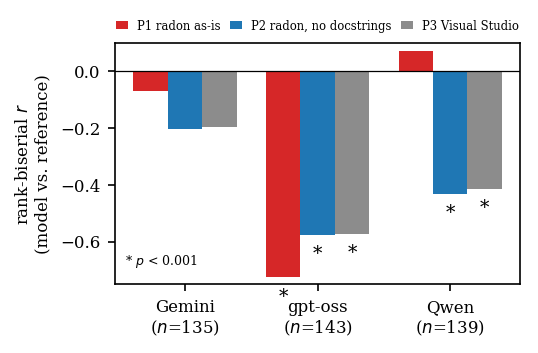

In [43]:
# Fig. — perbandingan LLM vs referensi: rank-biserial per protokol (sama dengan fig_llm.png di paper)
if not L.empty:
    order = [l for l in ["gemini-lite", "gpt-oss", "qwen"] if l in S.columns]
    names = {"gemini-lite": "Gemini", "gpt-oss": "gpt-oss", "qwen": "Qwen"}
    protos = [("P1", "P1 radon as-is", "#d62728"), ("P2", "P2 radon, no docstrings", "#1f77b4"),
              ("P3", "P3 Visual Studio", "0.55")]
    fig, ax = plt.subplots(figsize=(3.45, 2.2))
    w = 0.26
    for k, (P, lab, col) in enumerate(protos):
        xs = [i + (k - 1) * w for i in range(len(order))]
        vals = [float(S.loc[f"{P} rank-biserial", m]) for m in order]
        ax.bar(xs, vals, w, color=col, label=lab)
        for x, v, m in zip(xs, vals, order):
            p = S.loc[f"{P} wilcoxon p", m]
            if p is not None and float(p) < 0.001:
                ax.text(x, v - 0.035, "*", ha="center", va="top", fontsize=9)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(range(len(order)),
                  [f"{names[m]}\n($n$={int(S.loc['n_analysed', m])})" for m in order])
    ax.set_ylim(-0.75, 0.1)
    ax.set_ylabel("rank-biserial $r$\n(model vs. reference)")
    ax.legend(fontsize=5.6, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0),
              ncol=3, handlelength=1.0, columnspacing=0.8)
    ax.text(-0.45, -0.70, "* $p$ < 0.001", ha="left", va="bottom", fontsize=6)
    fig.tight_layout(pad=0.2)
    fig.savefig(FIG / "fig_llm.png", dpi=300); plt.show()